# UAV Communication Digital Twin Fidelity Estimation

This notebook merges UAV telemetry, SNR, and cumulative download measurements; trains Random Forest and neural-network models; estimates uncertainty with Monte Carlo Dropout; and evaluates predictions on chronological train/validation/test splits.

**Evaluation note:** the test segment is nearly constant for several download targets, so the persistence baseline can outperform the neural network. Interpret results as evidence for this recorded flight segment, not proof of general performance on other flights. The custom fidelity score is a relative-error-based project metric, not a standard calibrated fidelity measure.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim

print("Environment setup complete!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


Environment setup complete!
NumPy: 2.1.3
Pandas: 2.2.3
PyTorch: 2.11.0+cpu
GPU available: False


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
import pandas as pd

base_path = (
    "/content/drive/MyDrive/AADM2025Dryad/"
    "USRP/Post-processing/other plots"
)

snr_df = pd.read_csv(os.path.join(base_path, "vehicleOut_snr.csv"))
download_df = pd.read_csv(os.path.join(base_path, "vehicleOut_download.csv"))
telemetry_df = pd.read_csv(os.path.join(base_path, "vehicleOut.csv"))

for name, data in [
    ("SNR measurements", snr_df),
    ("Download measurements", download_df),
    ("UAV telemetry", telemetry_df)
]:
    print(f"\n{'=' * 60}")
    print(name)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    display(data.head(3))


SNR measurements
Shape: (653, 18)
Columns: ['time', 'snr_lw1', 'snr_lw2', 'snr_lw3', 'snr_lw4', 'num', 'Longitude', 'Latitude', 'Altitude', 'Pitch', 'Yaw', 'Roll', 'VelocityX', 'VelocityY', 'VelocityZ', 'BatteryVolts', 'GPSFix', 'NumberOfSatellites']


,time,snr_lw1,snr_lw2,snr_lw3,snr_lw4,num,Longitude,Latitude,Altitude,Pitch,Yaw,Roll,VelocityX,VelocityY,VelocityZ,BatteryVolts,GPSFix,NumberOfSatellites
0,2025-09-11 09:42:36.723,16.991161,3.003716,-8.437147,-42.354614,53.872516,-78.696213,35.727488,24.770705,-0.012755,-0.135865,0.007637,0.020397,0.098526,-0.503941,47.447020,4,27.0
1,2025-09-11 09:42:37.713,19.981956,7.073185,-8.402077,-43.892475,54.861274,-78.696212,35.727488,24.912012,-0.021285,-0.136722,-0.004657,-0.077515,0.084162,0.000637,47.282358,4,27.0
2,2025-09-11 09:42:38.716,22.448002,8.775846,-7.767447,-45.358917,55.863635,-78.696212,35.727487,24.903864,-0.032900,-0.138731,-0.008535,-0.159091,0.054091,-0.085454,47.270682,4,27.0



Download measurements
Shape: (652, 18)
Columns: ['time', 'dl_lw1', 'dl_lw2', 'dl_lw3', 'dl_lw4', 'num', 'Longitude', 'Latitude', 'Altitude', 'Pitch', 'Yaw', 'Roll', 'VelocityX', 'VelocityY', 'VelocityZ', 'BatteryVolts', 'GPSFix', 'NumberOfSatellites']


,time,dl_lw1,dl_lw2,dl_lw3,dl_lw4,num,Longitude,Latitude,Altitude,Pitch,Yaw,Roll,VelocityX,VelocityY,VelocityZ,BatteryVolts,GPSFix,NumberOfSatellites
0,2025-09-11 09:42:37.713,5.46,0.0,0.0,0.0,54.861218,-78.696212,35.727488,24.912008,-0.021284,-0.136721,-0.004656,-0.077510,0.084163,0.000609,47.282369,4,27.0
1,2025-09-11 09:42:38.716,11.79,0.0,0.0,0.0,55.863561,-78.696212,35.727487,24.903865,-0.032899,-0.138731,-0.008535,-0.159085,0.054093,-0.085441,47.270681,4,27.0
2,2025-09-11 09:42:39.716,18.96,0.0,0.0,0.0,56.862021,-78.696212,35.727486,24.914792,-0.039771,-0.137646,-0.010474,-0.144139,0.006899,-0.118620,47.312653,4,27.0



UAV telemetry
Shape: (716, 14)
Columns: ['num', 'Longitude', 'Latitude', 'Altitude', 'Pitch', 'Yaw', 'Roll', 'VelocityX', 'VelocityY', 'VelocityZ', 'BatteryVolts', 'time', 'GPSFix', 'NumberOfSatellites']


,num,Longitude,Latitude,Altitude,Pitch,Yaw,Roll,VelocityX,VelocityY,VelocityZ,BatteryVolts,time,GPSFix,NumberOfSatellites
0,1,-78.696212,35.727486,-3.909,0.033684,-0.041284,-0.106412,0.0,0.00,0.0,49.850,2025-09-11 09:41:43.810144,4,27
1,2,-78.696212,35.727486,-3.915,0.034004,-0.041103,-0.106485,0.0,0.00,0.0,49.836,2025-09-11 09:41:44.810981,4,27
2,3,-78.696212,35.727486,-3.922,0.033859,-0.041142,-0.106407,0.0,-0.01,0.0,49.847,2025-09-11 09:41:45.811401,4,27


In [10]:
# Convert timestamps to datetime
for data in [snr_df, download_df, telemetry_df]:
    data["time"] = pd.to_datetime(data["time"], errors="coerce")

print("TIMESTAMP CHECK")
for name, data in [
    ("SNR", snr_df),
    ("Download", download_df),
    ("Telemetry", telemetry_df)
]:
    print(f"\n{name}:")
    print("Missing timestamps:", data["time"].isna().sum())
    print("Duplicate timestamps:", data["time"].duplicated().sum())
    print("Time range:", data["time"].min(), "to", data["time"].max())

print("\nDOWNLOAD TARGET QUALITY")
target_cols = ["dl_lw1", "dl_lw2", "dl_lw3", "dl_lw4"]

display(download_df[target_cols].describe().T)

print("\nMissing target values:")
print(download_df[target_cols].isna().sum())

print("\nZero-valued target readings:")
print((download_df[target_cols] == 0).sum())

TIMESTAMP CHECK

SNR:
Missing timestamps: 0
Duplicate timestamps: 0
Time range: 2025-09-11 09:42:36.723000 to 2025-09-11 09:53:38.546000

Download:
Missing timestamps: 0
Duplicate timestamps: 0
Time range: 2025-09-11 09:42:37.713000 to 2025-09-11 09:53:38.546000

Telemetry:
Missing timestamps: 0
Duplicate timestamps: 0
Time range: 2025-09-11 09:41:43.810144 to 2025-09-11 09:53:39.497634

DOWNLOAD TARGET QUALITY


,count,mean,std,min,25%,50%,75%,max
dl_lw1,652.0,561.740721,119.295938,5.46,600.0000,600.000,600.0000,600.00
dl_lw2,652.0,459.342945,239.028106,0.00,374.1075,600.000,600.0000,600.00
dl_lw3,652.0,175.691426,254.706332,0.00,0.0000,0.000,491.1225,600.00
dl_lw4,652.0,11.547684,10.364653,0.00,0.0000,19.155,21.6600,21.66



Missing target values:
dl_lw1    0
dl_lw2    0
dl_lw3    0
dl_lw4    0
dtype: int64

Zero-valued target readings:
dl_lw1      0
dl_lw2     83
dl_lw3    380
dl_lw4    200
dtype: int64


In [11]:
# Sort all datasets by timestamp
snr_sorted = snr_df.sort_values("time").copy()
download_sorted = download_df.sort_values("time").copy()
telemetry_sorted = telemetry_df.sort_values("time").copy()

# Merge SNR and download measurements on their timestamps
communication_df = pd.merge_asof(
    download_sorted,
    snr_sorted[
        ["time", "snr_lw1", "snr_lw2", "snr_lw3", "snr_lw4"]
    ],
    on="time",
    direction="nearest",
    tolerance=pd.Timedelta("2s")
)

# Attach the nearest UAV telemetry record
telemetry_cols = [
    "time", "Longitude", "Latitude", "Altitude",
    "Pitch", "Yaw", "Roll",
    "VelocityX", "VelocityY", "VelocityZ",
    "BatteryVolts", "GPSFix", "NumberOfSatellites"
]

communication_df = pd.merge_asof(
    communication_df.sort_values("time"),
    telemetry_sorted[telemetry_cols].sort_values("time"),
    on="time",
    direction="nearest",
    tolerance=pd.Timedelta("2s"),
    suffixes=("", "_telemetry")
)

print("Merged dataset shape:", communication_df.shape)
print("\nMissing values after merging:")
print(communication_df.isna().sum())
print("\nFirst 5 merged records:")
display(communication_df.head())

Merged dataset shape: (652, 34)

Missing values after merging:
time                            0
dl_lw1                          0
dl_lw2                          0
dl_lw3                          0
dl_lw4                          0
num                             0
Longitude                       0
Latitude                        0
Altitude                        0
Pitch                           0
Yaw                             0
Roll                            0
VelocityX                       0
VelocityY                       0
VelocityZ                       0
BatteryVolts                    0
GPSFix                          0
NumberOfSatellites              0
snr_lw1                         0
snr_lw2                         0
snr_lw3                         0
snr_lw4                         0
Longitude_telemetry             0
Latitude_telemetry              0
Altitude_telemetry              0
Pitch_telemetry                 0
Yaw_telemetry                   0
Roll_telemetry     

,time,dl_lw1,dl_lw2,dl_lw3,dl_lw4,num,Longitude,Latitude,Altitude,Pitch,...,Altitude_telemetry,Pitch_telemetry,Yaw_telemetry,Roll_telemetry,VelocityX_telemetry,VelocityY_telemetry,VelocityZ_telemetry,BatteryVolts_telemetry,GPSFix_telemetry,NumberOfSatellites_telemetry
0,2025-09-11 09:42:37.713,5.46,0.0,0.0,0.0,54.861218,-78.696212,35.727488,24.912008,-0.021284,...,24.922,-0.022658,-0.136889,-0.006468,-0.09,0.08,0.07,47.256,4,27
1,2025-09-11 09:42:38.716,11.79,0.0,0.0,0.0,55.863561,-78.696212,35.727487,24.903865,-0.032899,...,24.901,-0.034517,-0.139022,-0.008861,-0.17,0.05,-0.11,47.273,4,27
2,2025-09-11 09:42:39.716,18.96,0.0,0.0,0.0,56.862021,-78.696212,35.727486,24.914792,-0.039771,...,24.917,-0.040612,-0.137426,-0.010732,-0.14,0.00,-0.12,47.319,4,27
3,2025-09-11 09:42:40.717,25.28,0.0,0.0,0.0,57.862203,-78.696212,35.727485,24.959248,-0.039192,...,24.966,-0.038965,-0.136877,-0.010343,-0.08,-0.07,-0.06,47.334,4,27
4,2025-09-11 09:42:41.728,30.74,0.0,0.0,0.0,58.872624,-78.696213,35.727484,24.938076,-0.050509,...,24.934,-0.052194,-0.939973,0.021966,0.05,-0.17,0.00,47.226,4,27


In [12]:
# Remove duplicate telemetry columns added during the second merge
duplicate_cols = [
    col for col in communication_df.columns
    if col.endswith("_telemetry")
]

communication_df = communication_df.drop(columns=duplicate_cols)

# Sort records chronologically
communication_df = communication_df.sort_values("time").reset_index(drop=True)

print("Cleaned dataset shape:", communication_df.shape)
print("\nRemaining columns:")
print(communication_df.columns.tolist())

print("\nMissing values:", communication_df.isna().sum().sum())
print("Duplicate rows:", communication_df.duplicated().sum())

display(communication_df.head(3))

Cleaned dataset shape: (652, 22)

Remaining columns:
['time', 'dl_lw1', 'dl_lw2', 'dl_lw3', 'dl_lw4', 'num', 'Longitude', 'Latitude', 'Altitude', 'Pitch', 'Yaw', 'Roll', 'VelocityX', 'VelocityY', 'VelocityZ', 'BatteryVolts', 'GPSFix', 'NumberOfSatellites', 'snr_lw1', 'snr_lw2', 'snr_lw3', 'snr_lw4']

Missing values: 0
Duplicate rows: 0


,time,dl_lw1,dl_lw2,dl_lw3,dl_lw4,num,Longitude,Latitude,Altitude,Pitch,...,VelocityX,VelocityY,VelocityZ,BatteryVolts,GPSFix,NumberOfSatellites,snr_lw1,snr_lw2,snr_lw3,snr_lw4
0,2025-09-11 09:42:37.713,5.46,0.0,0.0,0.0,54.861218,-78.696212,35.727488,24.912008,-0.021284,...,-0.077510,0.084163,0.000609,47.282369,4,27.0,19.981956,7.073185,-8.402077,-43.892475
1,2025-09-11 09:42:38.716,11.79,0.0,0.0,0.0,55.863561,-78.696212,35.727487,24.903865,-0.032899,...,-0.159085,0.054093,-0.085441,47.270681,4,27.0,22.448002,8.775846,-7.767447,-45.358917
2,2025-09-11 09:42:39.716,18.96,0.0,0.0,0.0,56.862021,-78.696212,35.727486,24.914792,-0.039771,...,-0.144139,0.006899,-0.118620,47.312653,4,27.0,19.383247,8.829218,-7.015853,-43.840973


In [13]:
# Input features: signal quality and UAV flight conditions
feature_cols = [
    "snr_lw1", "snr_lw2", "snr_lw3", "snr_lw4",
    "Longitude", "Latitude", "Altitude",
    "Pitch", "Yaw", "Roll",
    "VelocityX", "VelocityY", "VelocityZ",
    "BatteryVolts", "GPSFix", "NumberOfSatellites"
]

# Prediction targets: observed download measurements
target_cols = ["dl_lw1", "dl_lw2", "dl_lw3", "dl_lw4"]

X = communication_df[feature_cols].copy()
y = communication_df[target_cols].copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(feature_cols)

print("\nPrediction targets:")
print(target_cols)

print("\nTarget summary:")
display(y.describe().T)

Input feature shape: (652, 16)
Target shape: (652, 4)

Input features:
['snr_lw1', 'snr_lw2', 'snr_lw3', 'snr_lw4', 'Longitude', 'Latitude', 'Altitude', 'Pitch', 'Yaw', 'Roll', 'VelocityX', 'VelocityY', 'VelocityZ', 'BatteryVolts', 'GPSFix', 'NumberOfSatellites']

Prediction targets:
['dl_lw1', 'dl_lw2', 'dl_lw3', 'dl_lw4']

Target summary:


,count,mean,std,min,25%,50%,75%,max
dl_lw1,652.0,561.740721,119.295938,5.46,600.0000,600.000,600.0000,600.00
dl_lw2,652.0,459.342945,239.028106,0.00,374.1075,600.000,600.0000,600.00
dl_lw3,652.0,175.691426,254.706332,0.00,0.0000,0.000,491.1225,600.00
dl_lw4,652.0,11.547684,10.364653,0.00,0.0000,19.155,21.6600,21.66


In [14]:
# Keep the records in chronological order
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_val = X.iloc[train_end:val_end].copy()
y_val = y.iloc[train_end:val_end].copy()

X_test = X.iloc[val_end:].copy()
y_test = y.iloc[val_end:].copy()

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nChronological boundaries:")
print("Training:", communication_df["time"].iloc[0],
      "to", communication_df["time"].iloc[train_end - 1])
print("Validation:", communication_df["time"].iloc[train_end],
      "to", communication_df["time"].iloc[val_end - 1])
print("Testing:", communication_df["time"].iloc[val_end],
      "to", communication_df["time"].iloc[-1])

Training records: 456
Validation records: 98
Testing records: 98

Chronological boundaries:
Training: 2025-09-11 09:42:37.713000 to 2025-09-11 09:50:19.462000
Validation: 2025-09-11 09:50:20.470000 to 2025-09-11 09:51:58.957000
Testing: 2025-09-11 09:51:59.978000 to 2025-09-11 09:53:38.546000


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train the baseline model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Evaluate on validation data only
y_val_pred = rf_model.predict(X_val)

print("RANDOM FOREST — VALIDATION RESULTS\n")

for i, target in enumerate(target_cols):
    mae = mean_absolute_error(y_val.iloc[:, i], y_val_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_val.iloc[:, i], y_val_pred[:, i]))
    r2 = r2_score(y_val.iloc[:, i], y_val_pred[:, i])

    print(f"{target}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R²   : {r2:.4f}\n")

RANDOM FOREST — VALIDATION RESULTS

dl_lw1
  MAE  : 73.8145
  RMSE : 138.2646
  R²   : 0.0000

dl_lw2
  MAE  : 114.7055
  RMSE : 214.5621
  R²   : 0.0000

dl_lw3
  MAE  : 428.0388
  RMSE : 468.4004
  R²   : -22.7214

dl_lw4
  MAE  : 5.7795
  RMSE : 8.8029
  R²   : -3.2189



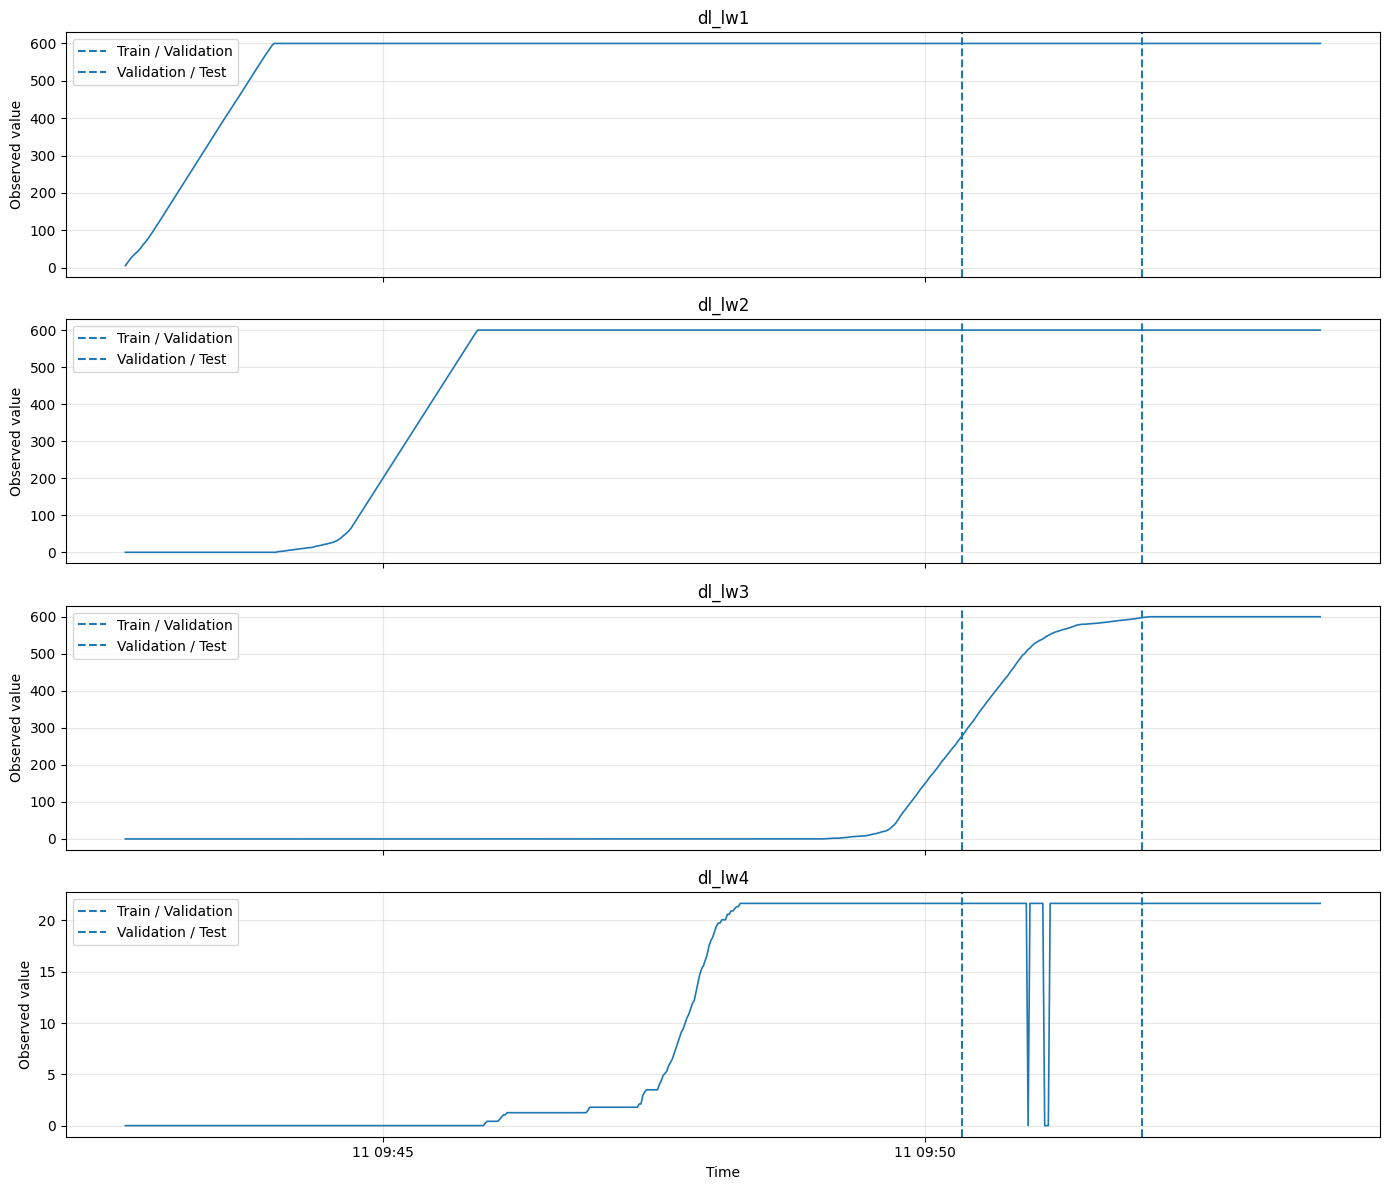

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

train_time_end = communication_df["time"].iloc[train_end]
val_time_end = communication_df["time"].iloc[val_end]

for ax, target in zip(axes, target_cols):
    ax.plot(
        communication_df["time"],
        communication_df[target],
        linewidth=1.2
    )

    ax.axvline(train_time_end, linestyle="--", label="Train / Validation")
    ax.axvline(val_time_end, linestyle="--", label="Validation / Test")

    ax.set_title(target)
    ax.set_ylabel("Observed value")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

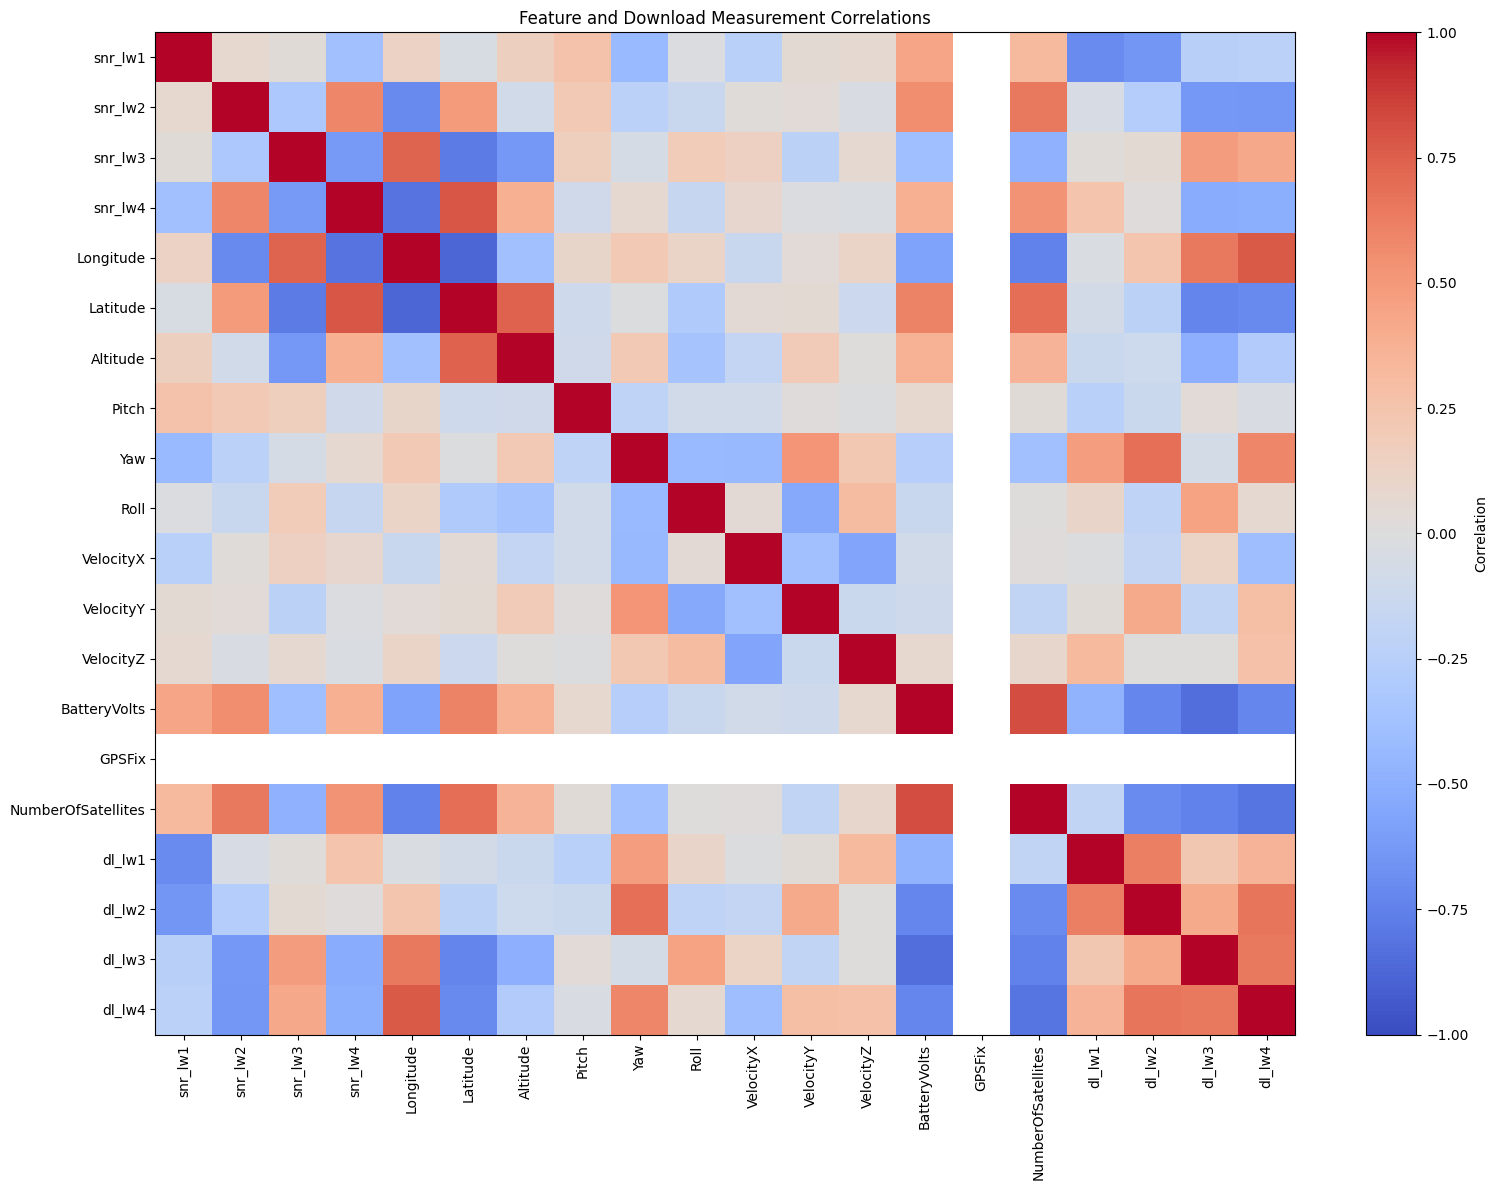

In [18]:
correlation_df = communication_df[feature_cols + target_cols].corr()

plt.figure(figsize=(16, 12))
plt.imshow(correlation_df, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_df.columns)),
    correlation_df.columns,
    rotation=90
)
plt.yticks(range(len(correlation_df.columns)), correlation_df.columns)
plt.title("Feature and Download Measurement Correlations")
plt.tight_layout()
plt.show()

In [19]:
results = []

for i, target in enumerate(target_cols):
    actual = y_val[target].to_numpy()
    rf_pred = y_val_pred[:, i]
    baseline_pred = np.full(len(actual), y_train[target].mean())

    results.append({
        "Link": target,
        "RF_MAE": mean_absolute_error(actual, rf_pred),
        "Baseline_MAE": mean_absolute_error(actual, baseline_pred),
        "RF_RMSE": np.sqrt(mean_squared_error(actual, rf_pred)),
        "Baseline_RMSE": np.sqrt(mean_squared_error(actual, baseline_pred))
    })

results_df = pd.DataFrame(results).round(3)
display(results_df)

,Link,RF_MAE,Baseline_MAE,RF_RMSE,Baseline_RMSE
0,dl_lw1,73.815,54.704,138.265,54.704
1,dl_lw2,114.705,201.115,214.562,201.115
2,dl_lw3,428.039,492.431,468.400,501.734
3,dl_lw4,5.780,13.988,8.803,14.054


In [20]:
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Fit scalers using training data only
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)

y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

print("Training input tensor:", X_train_tensor.shape)
print("Training target tensor:", y_train_tensor.shape)
print("Validation input tensor:", X_val_tensor.shape)
print("Validation target tensor:", y_val_tensor.shape)
print("\nPreprocessing complete.")

Training input tensor: torch.Size([456, 16])
Training target tensor: torch.Size([456, 4])
Validation input tensor: torch.Size([98, 16])
Validation target tensor: torch.Size([98, 4])

Preprocessing complete.


In [21]:
class FidelityNet(nn.Module):
    def __init__(self, input_size=16, output_size=4):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, output_size)
        )

    def forward(self, x):
        return self.network(x)


model = FidelityNet()

print(model)
print("\nTotal trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

FidelityNet(
  (network): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=4, bias=True)
  )
)

Total trainable parameters: 3300


In [22]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 200
train_losses = []
val_losses = []

for epoch in range(epochs):
    # Training
    model.train()
    optimizer.zero_grad()

    train_predictions = model(X_train_tensor)
    train_loss = criterion(train_predictions, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    # Validation
    model.eval()
    with torch.no_grad():
        val_predictions = model(X_val_tensor)
        val_loss = criterion(val_predictions, y_val_tensor)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {train_loss.item():.4f} "
            f"Validation Loss: {val_loss.item():.4f}"
        )

print("\nTraining complete!")

Epoch [20/200] Train Loss: 0.7383 Validation Loss: 27.0218
Epoch [40/200] Train Loss: 0.4326 Validation Loss: 23.5817
Epoch [60/200] Train Loss: 0.2876 Validation Loss: 21.3695
Epoch [80/200] Train Loss: 0.2406 Validation Loss: 19.9556
Epoch [100/200] Train Loss: 0.1998 Validation Loss: 19.0796
Epoch [120/200] Train Loss: 0.1783 Validation Loss: 18.4520
Epoch [140/200] Train Loss: 0.1637 Validation Loss: 17.9807
Epoch [160/200] Train Loss: 0.1366 Validation Loss: 17.8101
Epoch [180/200] Train Loss: 0.1328 Validation Loss: 17.8650
Epoch [200/200] Train Loss: 0.1280 Validation Loss: 17.3843

Training complete!


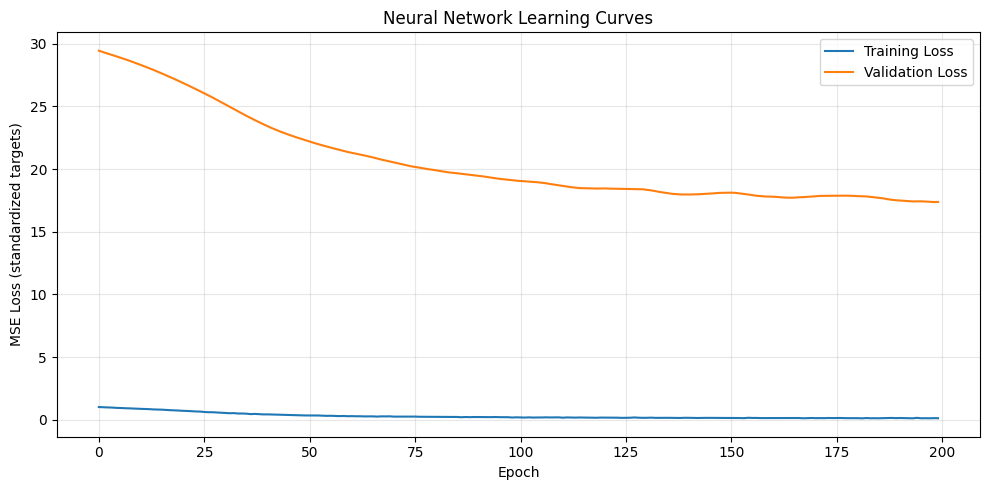

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss (standardized targets)")
plt.title("Neural Network Learning Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
model.eval()

with torch.no_grad():
    val_pred_scaled = model(X_val_tensor).numpy()

# Convert predictions back to the original measurement scale
val_pred = scaler_y.inverse_transform(val_pred_scaled)

print("NEURAL NETWORK — VALIDATION RESULTS\n")

for i, target in enumerate(target_cols):
    actual = y_val.iloc[:, i].to_numpy()
    predicted = val_pred[:, i]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"{target}")
    print(f"  MAE:  {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  R²:   {r2:.4f}")
    print()

NEURAL NETWORK — VALIDATION RESULTS

dl_lw1
  MAE:  12.0920
  RMSE: 20.5701
  R²:   0.0000

dl_lw2
  MAE:  38.8064
  RMSE: 52.0371
  R²:   0.0000

dl_lw3
  MAE:  372.6021
  RMSE: 391.1775
  R²:   -15.5445

dl_lw4
  MAE:  3.8008
  RMSE: 5.1449
  R²:   -0.4411



In [25]:
model.train()  # Keep dropout active during prediction

mc_predictions = []

with torch.no_grad():
    for _ in range(100):
        pred_scaled = model(X_val_tensor).numpy()
        pred_original = scaler_y.inverse_transform(pred_scaled)
        mc_predictions.append(pred_original)

mc_predictions = np.array(mc_predictions)

# Average prediction and estimated uncertainty
mc_mean = mc_predictions.mean(axis=0)
mc_std = mc_predictions.std(axis=0)

print("MONTE CARLO DROPOUT — VALIDATION\n")

for i, target in enumerate(target_cols):
    actual = y_val.iloc[:, i].to_numpy()

    mae = mean_absolute_error(actual, mc_mean[:, i])
    rmse = np.sqrt(mean_squared_error(actual, mc_mean[:, i]))
    mean_uncertainty = mc_std[:, i].mean()

    print(f"{target}")
    print(f"  MAE: {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  Mean predictive standard deviation: {mean_uncertainty:.4f}")
    print()

MONTE CARLO DROPOUT — VALIDATION

dl_lw1
  MAE: 16.2511
  RMSE: 22.3216
  Mean predictive standard deviation: 33.2960

dl_lw2
  MAE: 42.4801
  RMSE: 56.4473
  Mean predictive standard deviation: 64.5204

dl_lw3
  MAE: 374.0425
  RMSE: 392.3902
  Mean predictive standard deviation: 29.6769

dl_lw4
  MAE: 3.6591
  RMSE: 4.9874
  Mean predictive standard deviation: 3.2240



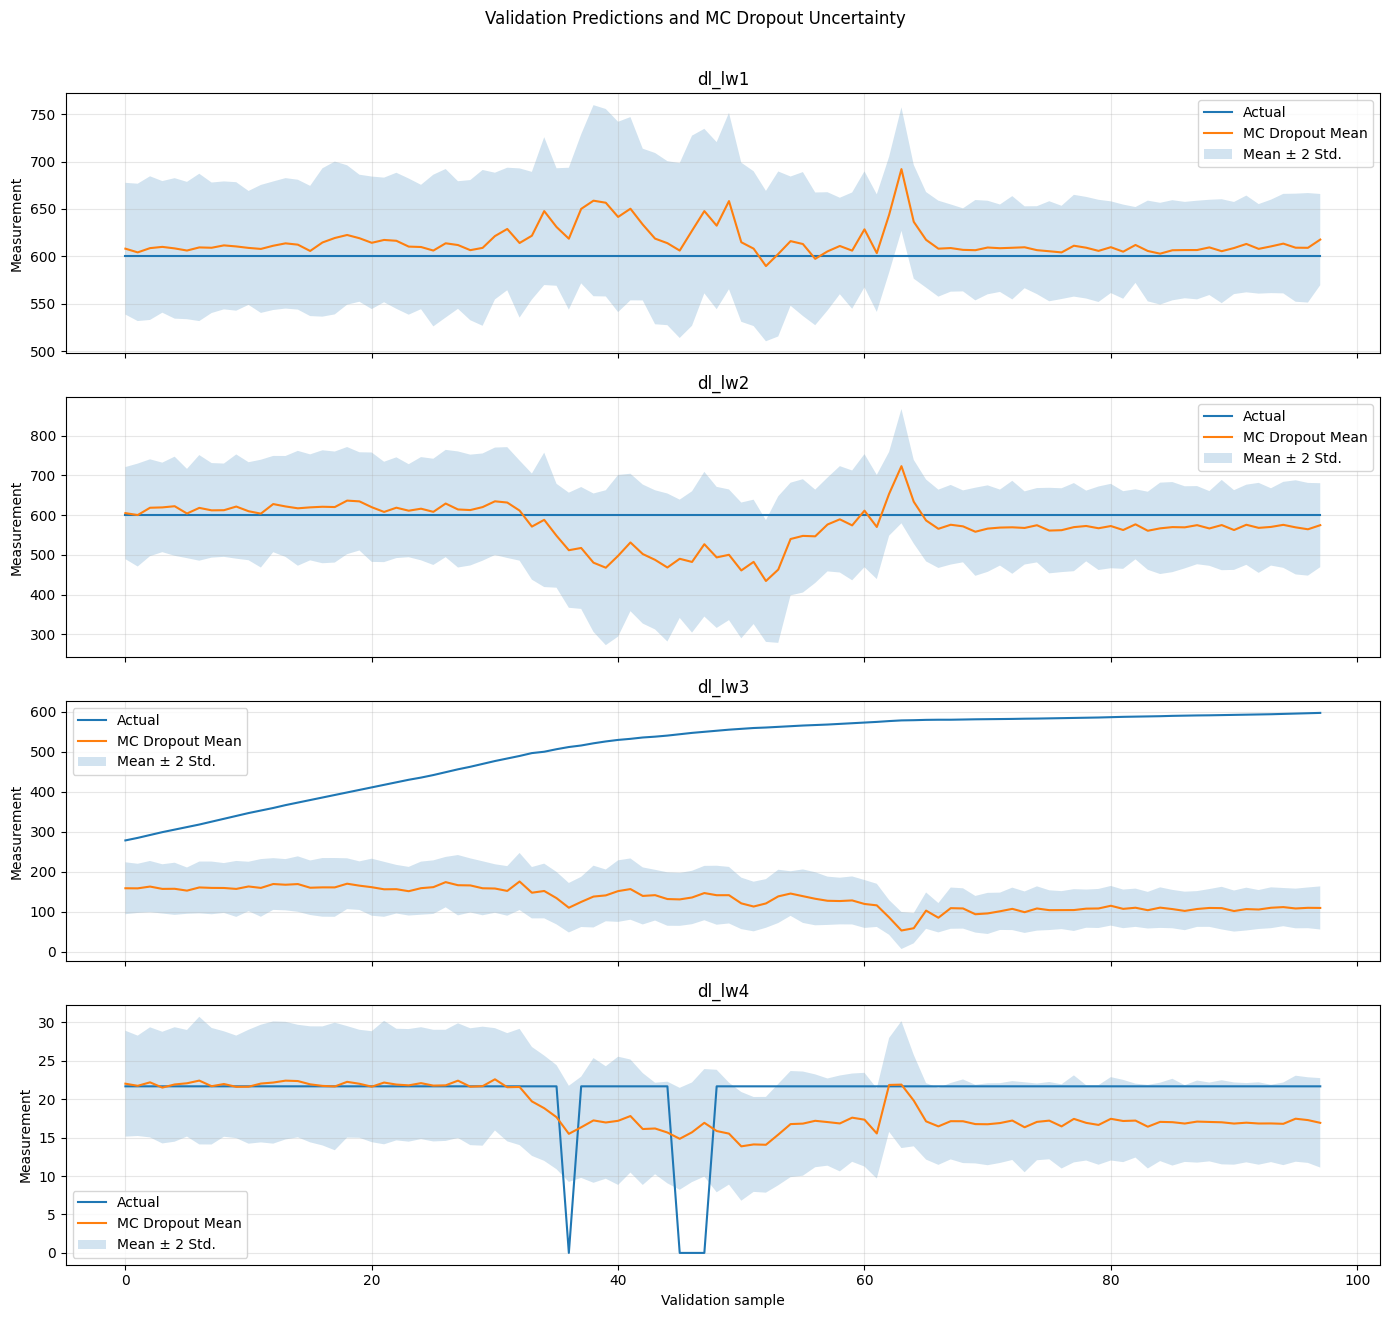

In [26]:
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)

for i, (ax, target) in enumerate(zip(axes, target_cols)):
    actual = y_val.iloc[:, i].to_numpy()
    mean_pred = mc_mean[:, i]
    uncertainty = mc_std[:, i]

    ax.plot(actual, label="Actual", linewidth=1.5)
    ax.plot(mean_pred, label="MC Dropout Mean", linewidth=1.5)
    ax.fill_between(
        np.arange(len(actual)),
        mean_pred - 2 * uncertainty,
        mean_pred + 2 * uncertainty,
        alpha=0.2,
        label="Mean ± 2 Std."
    )

    ax.set_title(target)
    ax.set_ylabel("Measurement")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Validation sample")
plt.suptitle("Validation Predictions and MC Dropout Uncertainty", y=1.01)
plt.tight_layout()
plt.show()

In [27]:
comparison_results = []

for i, target in enumerate(target_cols):
    actual = y_val.iloc[:, i].to_numpy()

    rf_pred = y_val_pred[:, i]
    nn_pred = val_pred[:, i]
    mc_pred = mc_mean[:, i]

    comparison_results.append({
        "Link": target,
        "RF_MAE": mean_absolute_error(actual, rf_pred),
        "NN_MAE": mean_absolute_error(actual, nn_pred),
        "MC_Dropout_MAE": mean_absolute_error(actual, mc_pred),
        "MC_Mean_Uncertainty": mc_std[:, i].mean()
    })

comparison_df = pd.DataFrame(comparison_results).round(3)
display(comparison_df)

,Link,RF_MAE,NN_MAE,MC_Dropout_MAE,MC_Mean_Uncertainty
0,dl_lw1,73.815,12.092,16.251,33.296001
1,dl_lw2,114.705,38.806,42.480,64.519997
2,dl_lw3,428.039,372.602,374.042,29.677000
3,dl_lw4,5.780,3.801,3.659,3.224000


In [29]:
fidelity_results_v2 = []

for i, target in enumerate(target_cols):
    actual = y_val.iloc[:, i].to_numpy()
    predicted = mc_mean[:, i]

    mae = mean_absolute_error(actual, predicted)
    scale = np.mean(np.abs(actual))

    if scale > 0:
        fidelity = max(0, 1 - mae / scale) * 100
    else:
        fidelity = np.nan

    fidelity_results_v2.append({
        "Link": target,
        "MAE": mae,
        "Mean_Absolute_Target": scale,
        "Fidelity_Score": fidelity
    })

fidelity_df_v2 = pd.DataFrame(fidelity_results_v2).round(3)
display(fidelity_df_v2)

,Link,MAE,Mean_Absolute_Target,Fidelity_Score
0,dl_lw1,16.251,600.000,97.291
1,dl_lw2,42.480,600.000,92.920
2,dl_lw3,374.042,505.966,26.074
3,dl_lw4,3.659,20.776,82.388


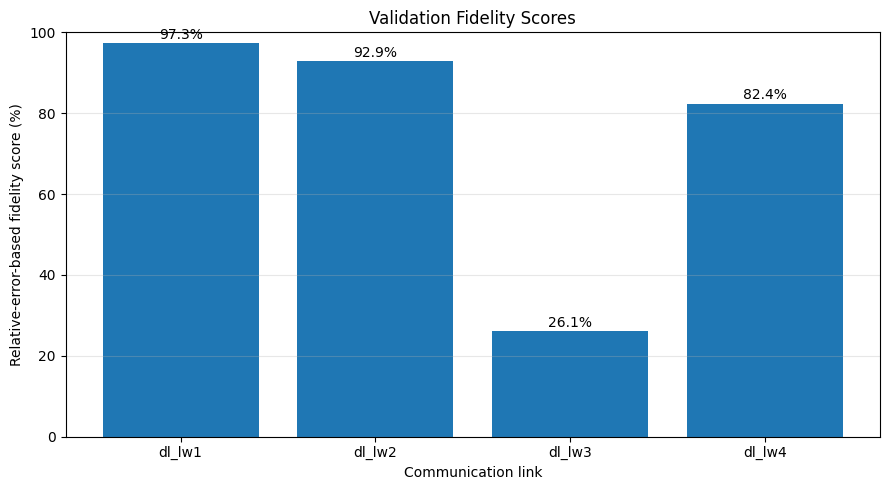

In [30]:
plot_df = fidelity_df_v2.dropna(subset=["Fidelity_Score"])

plt.figure(figsize=(9, 5))
bars = plt.bar(plot_df["Link"], plot_df["Fidelity_Score"])

plt.ylim(0, 100)
plt.ylabel("Relative-error-based fidelity score (%)")
plt.xlabel("Communication link")
plt.title("Validation Fidelity Scores")
plt.grid(axis="y", alpha=0.3)

for bar, score in zip(bars, plot_df["Fidelity_Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [31]:
# Investigate the dl_lw3 prediction problem

target = "dl_lw3"
i = target_cols.index(target)

diagnostics = pd.DataFrame({
    "Actual": y_val[target].to_numpy(),
    "Random_Forest": y_val_pred[:, i],
    "Neural_Network": val_pred[:, i],
    "MC_Dropout": mc_mean[:, i],
    "MC_Uncertainty": mc_std[:, i]
})

print("TRAINING DATA DISTRIBUTION")
display(y_train[target].describe().to_frame("Training"))

print("\nVALIDATION DATA DISTRIBUTION")
display(y_val[target].describe().to_frame("Validation"))

print("\nFIRST 15 VALIDATION PREDICTIONS")
display(diagnostics.head(15).round(2))

TRAINING DATA DISTRIBUTION


,Training
count,456.000000
mean,13.535395
std,47.079848
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,272.130000



VALIDATION DATA DISTRIBUTION


,Validation
count,98.000000
mean,505.966020
std,96.666171
min,278.460000
25%,436.922500
50%,553.635000
75%,582.227500
max,596.860000



FIRST 15 VALIDATION PREDICTIONS


,Actual,Random_Forest,Neural_Network,MC_Dropout,MC_Uncertainty
0,278.46,223.84,162.100006,159.009995,32.410000
1,284.79,198.79,163.500000,158.759995,30.700001
2,291.96,175.94,163.669998,163.229996,31.959999
3,299.12,219.74,157.809998,157.399994,30.760000
4,305.45,221.67,159.589996,157.669998,32.560001
5,311.78,227.01,157.369995,153.059998,28.900000
6,318.11,232.47,161.399994,161.029999,32.320000
7,325.28,219.05,161.899994,159.880005,32.900002
8,332.44,219.14,158.809998,159.669998,31.100000
9,339.61,219.22,162.070007,157.350006,34.910000


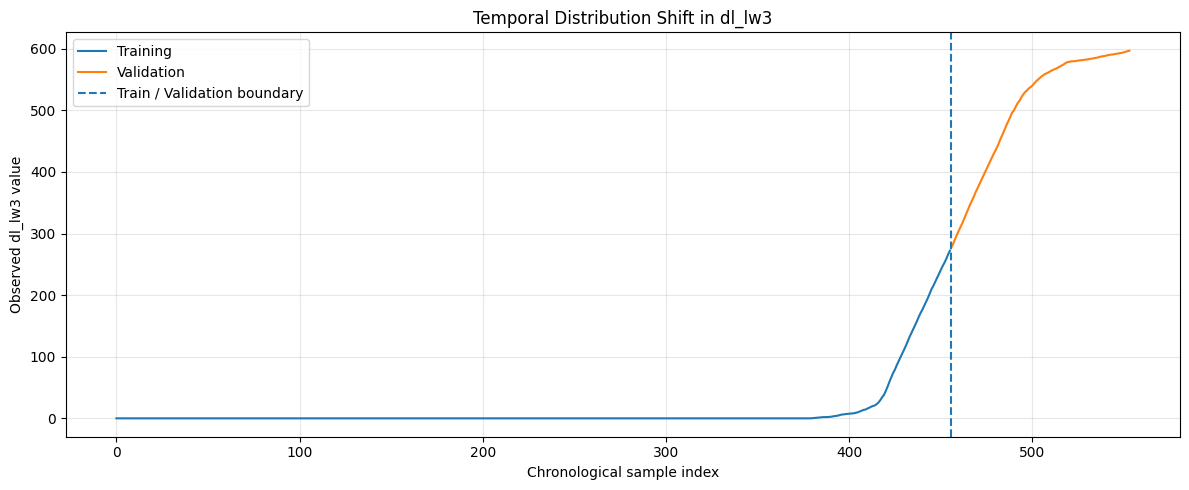

In [32]:
target = "dl_lw3"

plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(len(y_train)),
    y_train[target].to_numpy(),
    label="Training",
    linewidth=1.5
)

plt.plot(
    np.arange(len(y_train), len(y_train) + len(y_val)),
    y_val[target].to_numpy(),
    label="Validation",
    linewidth=1.5
)

plt.axvline(
    len(y_train) - 0.5,
    linestyle="--",
    label="Train / Validation boundary"
)

plt.xlabel("Chronological sample index")
plt.ylabel("Observed dl_lw3 value")
plt.title("Temporal Distribution Shift in dl_lw3")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
distribution_results = []

for target in target_cols:
    train_values = y_train[target]
    val_values = y_val[target]

    distribution_results.append({
        "Link": target,
        "Train_Mean": train_values.mean(),
        "Validation_Mean": val_values.mean(),
        "Train_Zero_%": (train_values == 0).mean() * 100,
        "Validation_Zero_%": (val_values == 0).mean() * 100,
        "Train_Max": train_values.max(),
        "Validation_Min": val_values.min()
    })

distribution_df = pd.DataFrame(distribution_results).round(2)
display(distribution_df)

,Link,Train_Mean,Validation_Mean,Train_Zero_%,Validation_Zero_%,Train_Max,Validation_Min
0,dl_lw1,545.30,600.00,0.00,0.00,600.00,600.00
1,dl_lw2,398.89,600.00,18.20,0.00,600.00,600.00
2,dl_lw3,13.54,505.97,83.33,0.00,272.13,278.46
3,dl_lw4,7.39,20.78,42.98,4.08,21.66,0.00


In [35]:
feature_shift_results = []

for feature in feature_cols:
    train_mean = X_train[feature].mean()
    val_mean = X_val[feature].mean()

    train_std = X_train[feature].std()
    val_std = X_val[feature].std()

    feature_shift_results.append({
        "Feature": feature,
        "Train_Mean": train_mean,
        "Validation_Mean": val_mean,
        "Train_Std": train_std,
        "Validation_Std": val_std
    })

feature_shift_df = pd.DataFrame(feature_shift_results).round(3)
display(feature_shift_df)

,Feature,Train_Mean,Validation_Mean,Train_Std,Validation_Std
0,snr_lw1,3.546,-2.048,10.496,3.543
1,snr_lw2,9.755,-2.912,9.988,4.544
2,snr_lw3,-9.795,9.234,14.288,9.490
3,snr_lw4,-24.053,-42.526,17.997,1.721
4,Longitude,-78.698,-78.693,0.003,0.001
5,Latitude,35.728,35.725,0.002,0.000
6,Altitude,38.330,24.993,13.695,0.051
7,Pitch,-0.041,-0.038,0.089,0.074
8,Yaw,-0.126,-0.098,1.926,1.332
9,Roll,-0.011,0.005,0.023,0.023


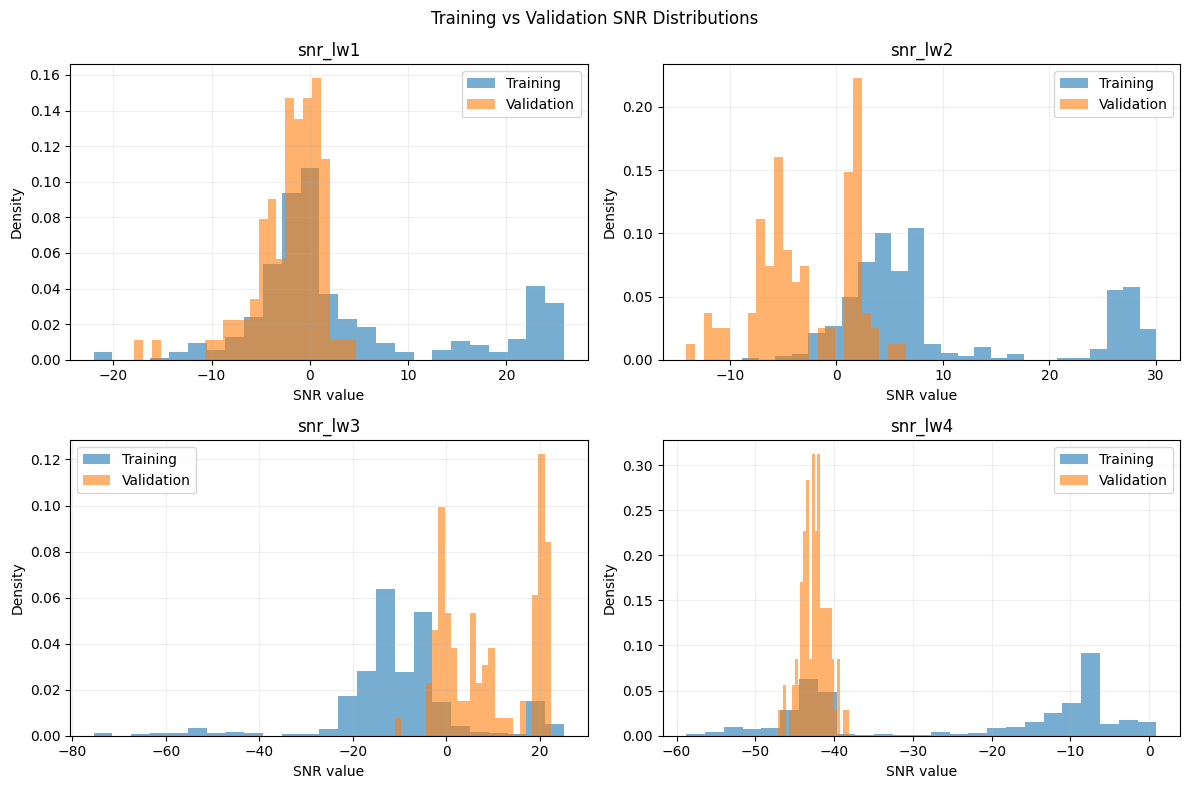

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, [
    "snr_lw1", "snr_lw2", "snr_lw3", "snr_lw4"
]):
    ax.hist(
        X_train[feature],
        bins=25,
        alpha=0.6,
        label="Training",
        density=True
    )

    ax.hist(
        X_val[feature],
        bins=25,
        alpha=0.6,
        label="Validation",
        density=True
    )

    ax.set_title(feature)
    ax.set_xlabel("SNR value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, alpha=0.2)

plt.suptitle("Training vs Validation SNR Distributions")
plt.tight_layout()
plt.show()

In [37]:
persistence_results = []

for target in target_cols:
    # Predict each validation sample using the immediately previous reading
    previous_values = communication_df[target].iloc[
        train_end - 1 : val_end - 1
    ].to_numpy()

    actual_values = y_val[target].to_numpy()

    persistence_mae = mean_absolute_error(
        actual_values,
        previous_values
    )

    nn_mae = mean_absolute_error(
        actual_values,
        mc_mean[:, target_cols.index(target)]
    )

    persistence_results.append({
        "Link": target,
        "Persistence_MAE": persistence_mae,
        "MC_Dropout_MAE": nn_mae
    })

persistence_df = pd.DataFrame(persistence_results).round(3)
display(persistence_df)

,Link,Persistence_MAE,MC_Dropout_MAE
0,dl_lw1,0.000,16.251
1,dl_lw2,0.000,42.480
2,dl_lw3,3.314,374.042
3,dl_lw4,0.884,3.659


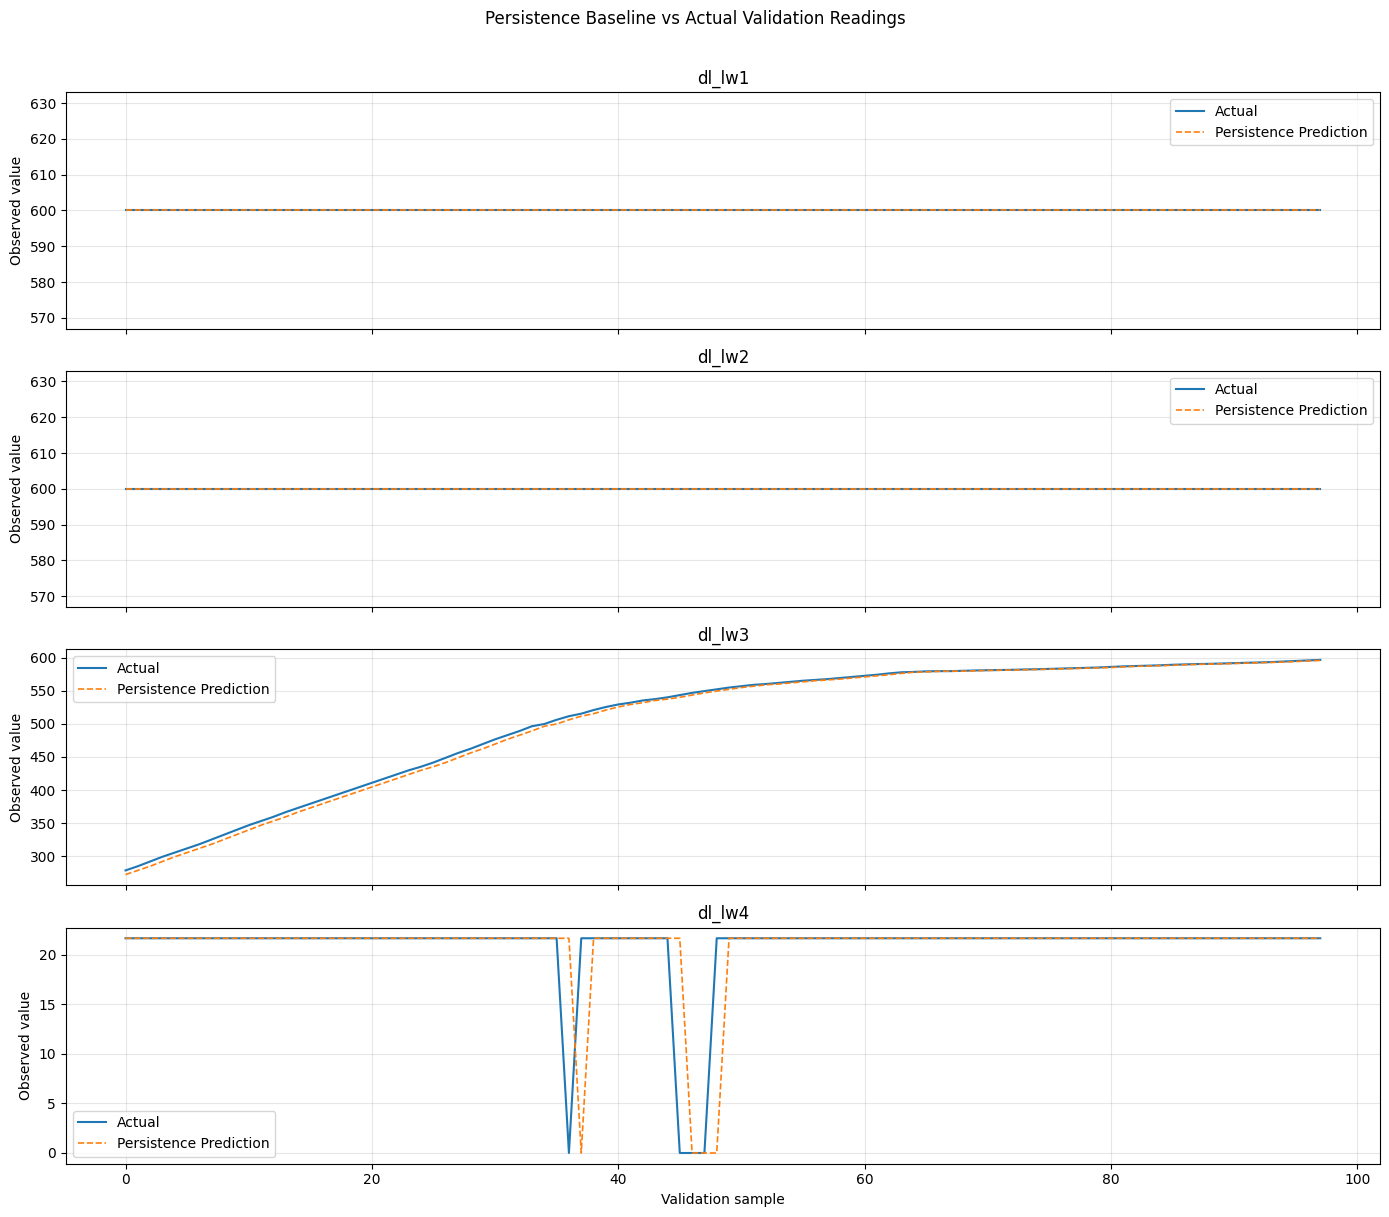

In [38]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

for i, (ax, target) in enumerate(zip(axes, target_cols)):
    actual = y_val[target].to_numpy()

    previous_values = communication_df[target].iloc[
        train_end - 1 : val_end - 1
    ].to_numpy()

    ax.plot(actual, label="Actual", linewidth=1.5)
    ax.plot(
        previous_values,
        label="Persistence Prediction",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_title(target)
    ax.set_ylabel("Observed value")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Validation sample")
plt.suptitle("Persistence Baseline vs Actual Validation Readings", y=1.01)
plt.tight_layout()
plt.show()

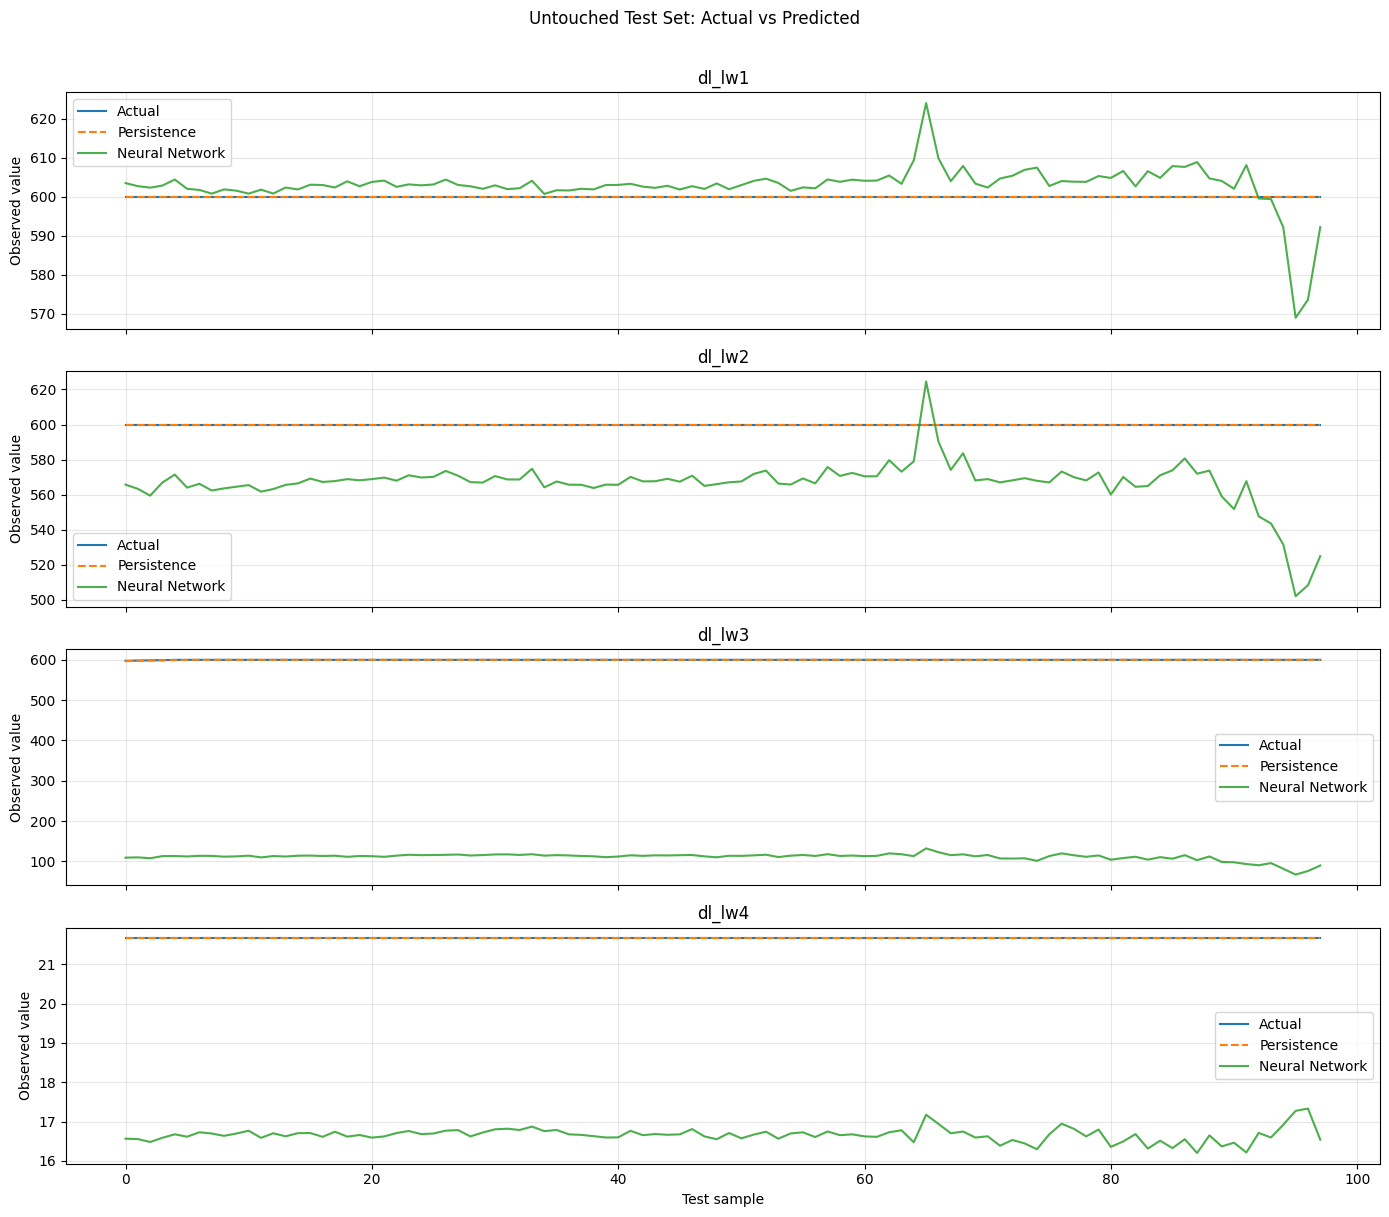

In [40]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

X_test_scaled = scaler_X.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

model.eval()
with torch.no_grad():
    nn_test_scaled = model(X_test_tensor).numpy()

nn_test_pred = scaler_y.inverse_transform(nn_test_scaled)

for i, (ax, target) in enumerate(zip(axes, target_cols)):
    actual = y_test[target].to_numpy()

    persistence_pred = communication_df[target].iloc[
        val_end - 1 : n - 1
    ].to_numpy()

    ax.plot(actual, label="Actual", linewidth=1.5)
    ax.plot(
        persistence_pred,
        label="Persistence",
        linestyle="--"
    )
    ax.plot(
        nn_test_pred[:, i],
        label="Neural Network",
        alpha=0.85
    )

    ax.set_title(target)
    ax.set_ylabel("Observed value")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Test sample")
plt.suptitle("Untouched Test Set: Actual vs Predicted", y=1.01)
plt.tight_layout()
plt.show()

TEST-SET PREDICTION ERROR SUMMARY


,dl_lw1_Absolute_Error,dl_lw2_Absolute_Error,dl_lw3_Absolute_Error,dl_lw4_Absolute_Error
count,98.000,98.000,98.000,98.000
mean,4.366,33.869,488.849,5.000
std,4.578,12.125,8.950,0.177
min,0.421,9.718,467.789,4.329
25%,2.235,29.353,484.673,4.921
50%,3.149,32.200,486.513,4.994
75%,4.464,34.395,488.654,5.067
max,31.013,97.935,532.782,5.459


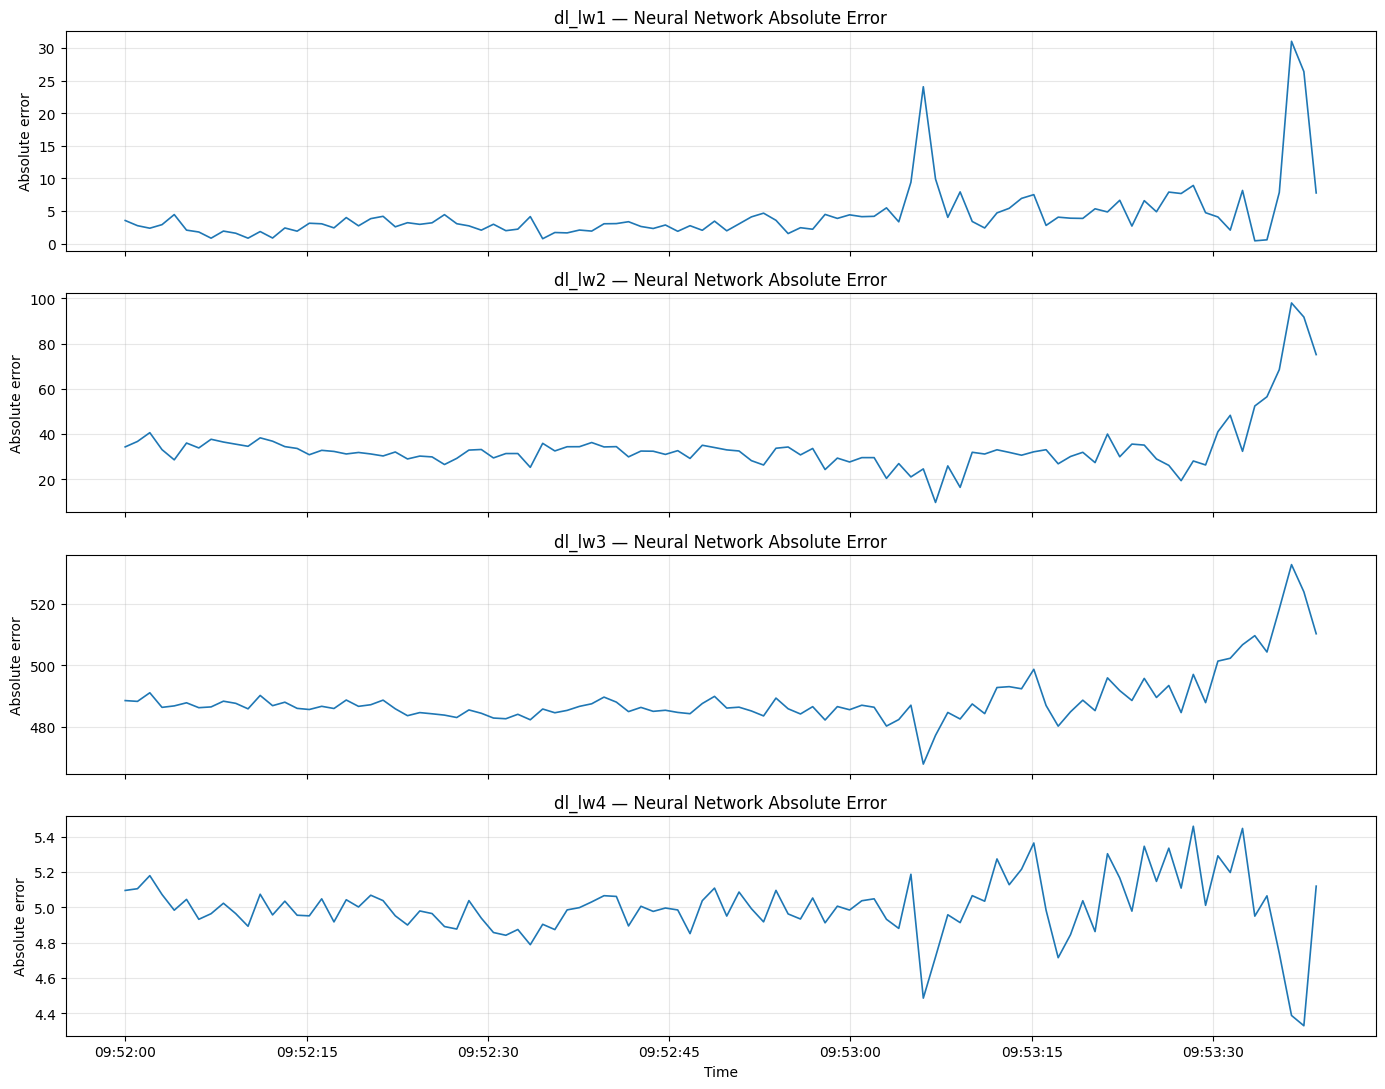

In [41]:
# Calculate absolute errors on the test set

test_error_df = pd.DataFrame({
    "time": communication_df["time"].iloc[val_end:].reset_index(drop=True)
})

for i, target in enumerate(target_cols):
    actual = y_test[target].to_numpy()
    predicted = nn_test_pred[:, i]

    test_error_df[f"{target}_Absolute_Error"] = np.abs(
        actual - predicted
    )

print("TEST-SET PREDICTION ERROR SUMMARY")
display(
    test_error_df[
        [f"{target}_Absolute_Error" for target in target_cols]
    ].describe().round(3)
)

# Plot the error timeline
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

for ax, target in zip(axes, target_cols):
    ax.plot(
        test_error_df["time"],
        test_error_df[f"{target}_Absolute_Error"],
        linewidth=1.2
    )
    ax.set_title(f"{target} — Neural Network Absolute Error")
    ax.set_ylabel("Absolute error")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

In [43]:
# Learn mismatch thresholds from validation errors only
mismatch_results = []

for i, target in enumerate(target_cols):
    val_actual = y_val[target].to_numpy()
    val_pred = mc_mean[:, i]

    val_errors = np.abs(val_actual - val_pred)
    threshold = np.percentile(val_errors, 95)

    test_errors = test_error_df[
        f"{target}_Absolute_Error"
    ].to_numpy()

    mismatch_flags = test_errors > threshold

    mismatch_results.append({
        "Link": target,
        "Validation_95th_Percentile_Error": threshold,
        "Test_Mismatch_Count": int(mismatch_flags.sum()),
        "Test_Samples": len(test_errors),
        "Test_Mismatch_Percentage": mismatch_flags.mean() * 100
    })

mismatch_df = pd.DataFrame(mismatch_results).round(3)
display(mismatch_df)

,Link,Validation_95th_Percentile_Error,Test_Mismatch_Count,Test_Samples,Test_Mismatch_Percentage
0,dl_lw1,50.105,0,98,0.000
1,dl_lw2,124.740,0,98,0.000
2,dl_lw3,487.914,33,98,33.673
3,dl_lw4,7.630,0,98,0.000


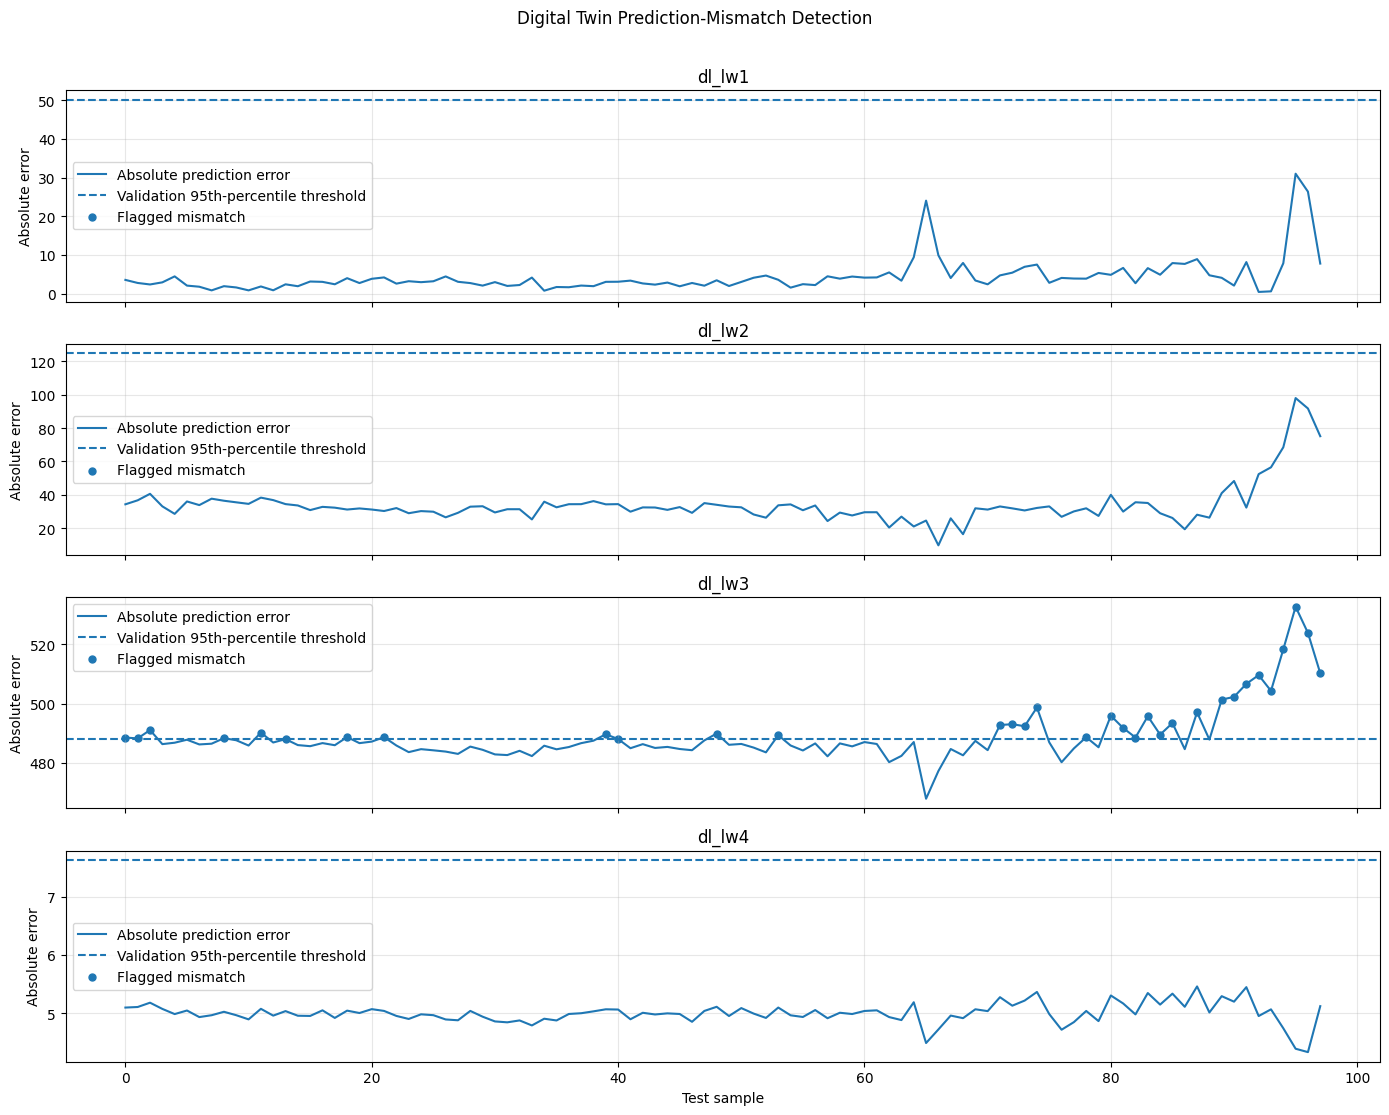

In [44]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

for ax, target in zip(axes, target_cols):
    errors = test_error_df[
        f"{target}_Absolute_Error"
    ].to_numpy()

    threshold = mismatch_df.loc[
        mismatch_df["Link"] == target,
        "Validation_95th_Percentile_Error"
    ].iloc[0]

    flagged = errors > threshold

    ax.plot(errors, label="Absolute prediction error")
    ax.axhline(
        threshold,
        linestyle="--",
        label="Validation 95th-percentile threshold"
    )

    ax.scatter(
        np.where(flagged)[0],
        errors[flagged],
        label="Flagged mismatch",
        s=25
    )

    ax.set_title(target)
    ax.set_ylabel("Absolute error")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Test sample")
plt.suptitle("Digital Twin Prediction-Mismatch Detection", y=1.01)
plt.tight_layout()
plt.show()

In [45]:
# Final test-set performance summary

final_results = []

for i, target in enumerate(target_cols):
    actual = y_test[target].to_numpy()

    nn_pred = nn_test_pred[:, i]

    persistence_pred = communication_df[target].iloc[
        val_end - 1 : n - 1
    ].to_numpy()

    nn_mae = mean_absolute_error(actual, nn_pred)
    nn_rmse = np.sqrt(mean_squared_error(actual, nn_pred))

    persistence_mae = mean_absolute_error(
        actual, persistence_pred
    )
    persistence_rmse = np.sqrt(
        mean_squared_error(actual, persistence_pred)
    )

    final_results.append({
        "Link": target,
        "NN_MAE": nn_mae,
        "NN_RMSE": nn_rmse,
        "Persistence_MAE": persistence_mae,
        "Persistence_RMSE": persistence_rmse,
        "Better_Model": (
            "Neural Network"
            if nn_mae < persistence_mae
            else "Persistence"
        )
    })

final_results_df = pd.DataFrame(final_results).round(3)

print("FINAL TEST-SET MODEL COMPARISON")
display(final_results_df)

print("\nOverall interpretation:")
print(
    "The persistence baseline achieved lower MAE than the neural "
    "network on all four links in this test segment."
)
print(
    "These results apply to this recorded flight and do not establish "
    "which model will generalize better to other flights."
)

FINAL TEST-SET MODEL COMPARISON


,Link,NN_MAE,NN_RMSE,Persistence_MAE,Persistence_RMSE,Better_Model
0,dl_lw1,4.366,6.309,0.000,0.000,Persistence
1,dl_lw2,33.869,35.953,0.000,0.000,Persistence
2,dl_lw3,488.849,488.930,0.032,0.145,Persistence
3,dl_lw4,5.000,5.003,0.000,0.000,Persistence



Overall interpretation:
The persistence baseline achieved lower MAE than the neural network on all four links in this test segment.
These results apply to this recorded flight and do not establish which model will generalize better to other flights.


In [46]:
# Overall test-set regression metrics

all_actual = y_test.to_numpy()
all_nn_pred = nn_test_pred

all_persistence_pred = np.column_stack([
    communication_df[target].iloc[val_end - 1 : n - 1].to_numpy()
    for target in target_cols
])

print("OVERALL TEST-SET PERFORMANCE\n")

print("Neural Network")
print("MAE:", round(mean_absolute_error(
    all_actual.ravel(), all_nn_pred.ravel()
), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(
    all_actual.ravel(), all_nn_pred.ravel()
)), 3))

print("\nPersistence Baseline")
print("MAE:", round(mean_absolute_error(
    all_actual.ravel(), all_persistence_pred.ravel()
), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(
    all_actual.ravel(), all_persistence_pred.ravel()
)), 3))

OVERALL TEST-SET PERFORMANCE

Neural Network
MAE: 133.021
RMSE: 245.158

Persistence Baseline
MAE: 0.008
RMSE: 0.072


In [51]:
# Inspect actual test-set variability

test_variability = []

for target in target_cols:
    actual = y_test[target]

    test_variability.append({
        "Link": target,
        "Unique_Values": actual.nunique(),
        "Mean": actual.mean(),
        "Standard_Deviation": actual.std(),
        "Minimum": actual.min(),
        "Maximum": actual.max(),
        "Range": actual.max() - actual.min()
    })

test_variability_df = pd.DataFrame(
    test_variability
).round(6)

print("TEST-SET TARGET VARIABILITY")
display(test_variability_df)

TEST-SET TARGET VARIABILITY


,Link,Unique_Values,Mean,Standard_Deviation,Minimum,Maximum,Range
0,dl_lw1,1,600.000000,0.000000,600.00,600.00,0.0
1,dl_lw2,1,600.000000,0.000000,600.00,600.00,0.0
2,dl_lw3,5,599.938776,0.322018,597.70,600.00,2.3
3,dl_lw4,1,21.660000,0.000000,21.66,21.66,0.0


In [58]:
# Consolidated final project results

final_summary = pd.DataFrame({
    "Link": target_cols,
    "NN_Test_MAE": [
        mean_absolute_error(
            y_test[target].to_numpy(),
            nn_test_pred[:, i]
        )
        for i, target in enumerate(target_cols)
    ],
    "Persistence_Test_MAE": [
        mean_absolute_error(
            y_test[target].to_numpy(),
            all_persistence_pred[:, i]
        )
        for i, target in enumerate(target_cols)
    ],
    "Mismatch_Count": [
        int(
            mismatch_df.loc[
                mismatch_df["Link"] == target,
                "Test_Mismatch_Count"
            ].iloc[0]
        )
        for target in target_cols
    ],
    "Test_Samples": len(y_test)
})

final_summary = final_summary.round(3)

print("FINAL DIGITAL TWIN EVALUATION SUMMARY")
display(final_summary)

print("\nOverall test MAE:")
print("Neural Network:", round(
    mean_absolute_error(
        y_test.to_numpy().ravel(),
        nn_test_pred.ravel()
    ), 3
))
print("Persistence:", round(
    mean_absolute_error(
        y_test.to_numpy().ravel(),
        all_persistence_pred.ravel()
    ), 3
))

FINAL DIGITAL TWIN EVALUATION SUMMARY


,Link,NN_Test_MAE,Persistence_Test_MAE,Mismatch_Count,Test_Samples
0,dl_lw1,4.366,0.000,0,98
1,dl_lw2,33.869,0.000,0,98
2,dl_lw3,488.849,0.032,33,98
3,dl_lw4,5.000,0.000,0,98



Overall test MAE:
Neural Network: 133.021
Persistence: 0.008


## EDA Report + Classification Metrics (Added; existing notebook cells unchanged)

Run this section **after the existing notebook cells have completed successfully**. It adds:
- Exploratory Data Analysis (EDA): dataset shape, missing values, duplicates, descriptive statistics, target variability, distributions, correlation heatmap, and time-series plots.
- Dashboard-style **Accuracy, Precision, Recall, F1-score**, per link and combined, plus a confusion matrix.
- A PDF report and CSV summaries saved to Google Drive.

**Important interpretation:** the four classification metrics require converting continuous throughput predictions into `Below` / `Above` classes. This cell follows the dashboard's exploratory approach, using each test target's 25th-percentile value as a provisional per-link threshold. These are *threshold-based exploratory metrics*, not standard regression accuracy. Keep MAE/RMSE/R² and fidelity results for the continuous prediction task. The test-percentile threshold is for dashboard comparability, not formal unbiased evaluation; use an engineering threshold or validation-derived threshold for formal reporting.


In [ ]:
# ============================================================
# ADD-ON: EDA REPORT + DASHBOARD-STYLE CLASSIFICATION METRICS
# Existing cells above are intentionally not modified.
# Run after the notebook's existing model/test cells.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)
from matplotlib.backends.backend_pdf import PdfPages

# Save outputs in Google Drive when mounted; otherwise use local Colab storage.
try:
    _drive_root = "/content/drive/MyDrive"
    if os.path.isdir(_drive_root):
        EDA_OUTPUT_DIR = os.path.join(_drive_root, "UAV_EDA_Report")
    else:
        EDA_OUTPUT_DIR = "/content/UAV_EDA_Report"
except Exception:
    EDA_OUTPUT_DIR = "/content/UAV_EDA_Report"

os.makedirs(EDA_OUTPUT_DIR, exist_ok=True)

# Use the already-created merged dataset and existing model predictions.
if "communication_df" not in globals():
    raise NameError("communication_df was not found. Run the notebook data preparation cells first.")
if "target_cols" not in globals() or "feature_cols" not in globals():
    raise NameError("feature_cols/target_cols not found. Run the notebook feature preparation cells first.")
if "y_test" not in globals() or "nn_test_pred" not in globals():
    raise NameError("Test targets or neural-network test predictions are missing. Run the existing model/test cells first.")

eda_df = communication_df.copy()
if "time" in eda_df.columns:
    eda_df["time"] = pd.to_datetime(eda_df["time"], errors="coerce")
    eda_df = eda_df.sort_values("time").reset_index(drop=True)

# ----------------------------
# 1. EDA data-quality summaries
# ----------------------------
missing_summary = eda_df.isna().sum().rename("Missing_Count").to_frame()
missing_summary["Missing_Percent"] = (missing_summary["Missing_Count"] / max(len(eda_df), 1) * 100).round(3)
duplicate_count = int(eda_df.duplicated().sum())
numeric_df = eda_df.select_dtypes(include=[np.number])
describe_df = numeric_df.describe().T if not numeric_df.empty else pd.DataFrame()
target_rows = []
for target in target_cols:
    if target not in eda_df.columns:
        continue
    vals = pd.to_numeric(eda_df[target], errors="coerce").dropna()
    target_rows.append({
        "Target": target,
        "Count": int(vals.size),
        "Unique_Values": int(vals.nunique()),
        "Minimum": float(vals.min()) if vals.size else np.nan,
        "Mean": float(vals.mean()) if vals.size else np.nan,
        "Median": float(vals.median()) if vals.size else np.nan,
        "Maximum": float(vals.max()) if vals.size else np.nan,
        "Std_Dev": float(vals.std()) if vals.size > 1 else 0.0
    })
target_variability_df = pd.DataFrame(target_rows)

print("=" * 72)
print("UAV COMMUNICATION DATA — EDA REPORT")
print("=" * 72)
print("Dataset shape:", eda_df.shape)
print("Duplicate rows:", duplicate_count)
print("Total missing cells:", int(eda_df.isna().sum().sum()))
if "time" in eda_df.columns and eda_df["time"].notna().any():
    print("Time range:", eda_df["time"].min(), "to", eda_df["time"].max())
print("\\nMissing values by column:")
display(missing_summary)
print("\\nNumeric descriptive statistics:")
display(describe_df.round(4))
print("\\nTarget variability:")
display(target_variability_df.round(4))

# ----------------------------
# 2. Dashboard-style classification metrics
# ----------------------------
# Test-set MC Dropout predictions (100 passes), keeping the existing trained model.
X_test_scaled_for_mc = scaler_X.transform(X_test)
X_test_tensor_for_mc = torch.tensor(X_test_scaled_for_mc, dtype=torch.float32)
mc_test_predictions = []
model.train()  # dropout active intentionally for Monte Carlo Dropout
with torch.no_grad():
    for _ in range(100):
        _pred_scaled = model(X_test_tensor_for_mc).cpu().numpy()
        mc_test_predictions.append(scaler_y.inverse_transform(_pred_scaled))
mc_test_predictions = np.asarray(mc_test_predictions)
mc_test_mean = mc_test_predictions.mean(axis=0)
mc_test_std = mc_test_predictions.std(axis=0)

actual_test = y_test[target_cols].to_numpy(dtype=float)
if actual_test.shape != mc_test_mean.shape:
    raise ValueError(
        f"Actual test shape {actual_test.shape} does not match MC prediction shape {mc_test_mean.shape}. "
        "No metrics were generated; verify the existing split and model outputs."
    )

classification_rows = []
confusion_matrices = {}
thresholds_used = {}
for i, target in enumerate(target_cols):
    actual = actual_test[:, i]
    predicted = mc_test_mean[:, i]
    valid = np.isfinite(actual) & np.isfinite(predicted)
    if not valid.any():
        continue
    actual_valid, pred_valid = actual[valid], predicted[valid]
    threshold = float(np.quantile(actual_valid, 0.25))
    thresholds_used[target] = threshold
    y_true_cls = (actual_valid >= threshold).astype(int)
    y_pred_cls = (pred_valid >= threshold).astype(int)
    cm = confusion_matrix(y_true_cls, y_pred_cls, labels=[0, 1])
    confusion_matrices[target] = cm
    classification_rows.append({
        "Link": target,
        "Threshold_25th_percentile": threshold,
        "Samples": int(valid.sum()),
        "Actual_Above": int(y_true_cls.sum()),
        "Predicted_Above": int(y_pred_cls.sum()),
        "Accuracy": float(accuracy_score(y_true_cls, y_pred_cls)),
        "Precision": float(precision_score(y_true_cls, y_pred_cls, zero_division=0)),
        "Recall": float(recall_score(y_true_cls, y_pred_cls, zero_division=0)),
        "F1_Score": float(f1_score(y_true_cls, y_pred_cls, zero_division=0)),
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })

classification_df = pd.DataFrame(classification_rows)
if not classification_df.empty:
    print("\\n" + "=" * 72)
    print("DASHBOARD-STYLE CLASSIFICATION METRICS (TEST SET)")
    print("Class rule: Below threshold = 0; At/above threshold = 1")
    print("Threshold is each link's 25th percentile of actual test values (exploratory).")
    print("=" * 72)
    display(classification_df.round(4))

    # Same combined calculation as the dashboard: stack valid labels across all links.
    combined_true, combined_pred = [], []
    for i, target in enumerate(target_cols):
        actual = actual_test[:, i]
        predicted = mc_test_mean[:, i]
        valid = np.isfinite(actual) & np.isfinite(predicted)
        if valid.any():
            cutoff = thresholds_used[target]
            combined_true.extend((actual[valid] >= cutoff).astype(int).tolist())
            combined_pred.extend((predicted[valid] >= cutoff).astype(int).tolist())
    combined_true = np.asarray(combined_true, dtype=int)
    combined_pred = np.asarray(combined_pred, dtype=int)
    combined_cm = confusion_matrix(combined_true, combined_pred, labels=[0, 1])
    combined_metrics_df = pd.DataFrame([{
        "Evaluation": "All links combined",
        "Samples": int(combined_true.size),
        "Accuracy": float(accuracy_score(combined_true, combined_pred)),
        "Precision": float(precision_score(combined_true, combined_pred, zero_division=0)),
        "Recall": float(recall_score(combined_true, combined_pred, zero_division=0)),
        "F1_Score": float(f1_score(combined_true, combined_pred, zero_division=0)),
        "TN": int(combined_cm[0, 0]), "FP": int(combined_cm[0, 1]),
        "FN": int(combined_cm[1, 0]), "TP": int(combined_cm[1, 1])
    }])
    print("\\nCOMBINED CLASSIFICATION METRICS")
    display(combined_metrics_df.round(4))
else:
    combined_metrics_df = pd.DataFrame()
    combined_cm = np.zeros((2, 2), dtype=int)
    print("Classification metrics skipped: no valid test predictions.")

# Also retain standard continuous-regression metrics; these are the primary metrics for throughput prediction.
regression_rows = []
for i, target in enumerate(target_cols):
    actual = actual_test[:, i]
    predicted = mc_test_mean[:, i]
    valid = np.isfinite(actual) & np.isfinite(predicted)
    if valid.any():
        regression_rows.append({
            "Link": target,
            "MAE": float(mean_absolute_error(actual[valid], predicted[valid])),
            "RMSE": float(np.sqrt(mean_squared_error(actual[valid], predicted[valid]))),
            "R2": float(r2_score(actual[valid], predicted[valid])) if valid.sum() > 1 else np.nan,
            "Mean_MC_Uncertainty_Std": float(mc_test_std[valid, i].mean())
        })
regression_df = pd.DataFrame(regression_rows)
print("\\nCONTINUOUS REGRESSION METRICS (TEST SET)")
display(regression_df.round(4))

# ----------------------------
# 3. EDA figures
# ----------------------------
eda_pdf_path = os.path.join(EDA_OUTPUT_DIR, "UAV_EDA_Report.pdf")
eda_summary_csv = os.path.join(EDA_OUTPUT_DIR, "EDA_Missing_Values.csv")
eda_describe_csv = os.path.join(EDA_OUTPUT_DIR, "EDA_Descriptive_Statistics.csv")
eda_target_csv = os.path.join(EDA_OUTPUT_DIR, "EDA_Target_Variability.csv")
classification_csv = os.path.join(EDA_OUTPUT_DIR, "Classification_Metrics.csv")
combined_csv = os.path.join(EDA_OUTPUT_DIR, "Combined_Classification_Metrics.csv")
regression_csv = os.path.join(EDA_OUTPUT_DIR, "Regression_Metrics.csv")

missing_summary.to_csv(eda_summary_csv)
describe_df.to_csv(eda_describe_csv)
target_variability_df.to_csv(eda_target_csv, index=False)
classification_df.to_csv(classification_csv, index=False)
combined_metrics_df.to_csv(combined_csv, index=False)
regression_df.to_csv(regression_csv, index=False)

with PdfPages(eda_pdf_path) as pdf:
    # Cover / summary page
    fig = plt.figure(figsize=(11.7, 8.3))
    fig.suptitle("UAV Communication Dataset — EDA Report", fontsize=20, fontweight="bold", y=0.95)
    summary_text = (
        f"Dataset rows: {len(eda_df):,}\\n"
        f"Dataset columns: {len(eda_df.columns):,}\\n"
        f"Duplicate rows: {duplicate_count:,}\\n"
        f"Missing cells: {int(eda_df.isna().sum().sum()):,}\\n"
        + (f"Time range: {eda_df['time'].min()} to {eda_df['time'].max()}\\n" if 'time' in eda_df.columns and eda_df['time'].notna().any() else "")
        + "\\nThis report describes the existing merged dataset. It does not modify training data or model parameters.\\n"
        + "Classification metrics use provisional per-link 25th-percentile thresholds and are exploratory."
    )
    fig.text(0.08, 0.78, summary_text, fontsize=13, va="top", linespacing=1.6)
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # EDA summary tables (target variability and numeric statistics)
    if not target_variability_df.empty:
        fig, ax = plt.subplots(figsize=(11.7, 5.5))
        ax.axis("off")
        ax.set_title("Download Target Variability", fontsize=15, pad=18)
        table_data = target_variability_df.round(4).astype(str).values
        table = ax.table(
            cellText=table_data,
            colLabels=target_variability_df.columns.tolist(),
            loc="center",
            cellLoc="center"
        )
        table.auto_set_font_size(False)
        table.set_fontsize(8)
        table.scale(1, 1.5)
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    if not describe_df.empty:
        stats_to_show = describe_df.round(3).reset_index().rename(columns={"index": "Column"})
        # Paginate long tables so all numeric summary statistics remain readable.
        chunk_size = 18
        for start in range(0, len(stats_to_show), chunk_size):
            chunk = stats_to_show.iloc[start:start + chunk_size]
            fig, ax = plt.subplots(figsize=(11.7, 7.5))
            ax.axis("off")
            ax.set_title("Numeric Descriptive Statistics", fontsize=15, pad=18)
            table = ax.table(
                cellText=chunk.astype(str).values,
                colLabels=chunk.columns.tolist(),
                loc="center",
                cellLoc="center"
            )
            table.auto_set_font_size(False)
            table.set_fontsize(7)
            table.scale(1, 1.25)
            fig.tight_layout()
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

    # Missingness bar chart
    fig, ax = plt.subplots(figsize=(11, 6))
    miss_plot = missing_summary.sort_values("Missing_Count", ascending=False)
    ax.bar(miss_plot.index.astype(str), miss_plot["Missing_Count"])
    ax.set_title("Missing Values by Column")
    ax.set_ylabel("Missing cell count")
    ax.tick_params(axis="x", rotation=75)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Target distributions
    available_targets = [c for c in target_cols if c in eda_df.columns]
    if available_targets:
        fig, axes = plt.subplots(len(available_targets), 1, figsize=(11, 3 * len(available_targets)))
        if len(available_targets) == 1:
            axes = [axes]
        for ax, target in zip(axes, available_targets):
            vals = pd.to_numeric(eda_df[target], errors="coerce").dropna()
            ax.hist(vals, bins=30)
            ax.set_title(f"Distribution: {target}")
            ax.set_xlabel("Recorded value")
            ax.set_ylabel("Frequency")
            ax.grid(alpha=0.2)
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    # Target time series
    if "time" in eda_df.columns and available_targets:
        fig, axes = plt.subplots(len(available_targets), 1, figsize=(12, 3 * len(available_targets)), sharex=True)
        if len(available_targets) == 1:
            axes = [axes]
        for ax, target in zip(axes, available_targets):
            ax.plot(eda_df["time"], pd.to_numeric(eda_df[target], errors="coerce"), linewidth=1)
            ax.set_title(f"{target} over time")
            ax.set_ylabel("Value")
            ax.grid(alpha=0.25)
        axes[-1].set_xlabel("Time")
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    # Correlation heatmap for numeric columns
    if numeric_df.shape[1] >= 2:
        corr = numeric_df.corr()
        fig, ax = plt.subplots(figsize=(12, 10))
        image = ax.imshow(corr.to_numpy(), aspect="auto", vmin=-1, vmax=1)
        ax.set_xticks(range(len(corr.columns)))
        ax.set_yticks(range(len(corr.columns)))
        ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
        ax.set_yticklabels(corr.columns, fontsize=7)
        ax.set_title("Correlation Heatmap — Numeric Variables")
        fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label="Correlation")
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    # Classification metric comparison chart
    if not classification_df.empty:
        fig, ax = plt.subplots(figsize=(11, 6))
        metric_cols = ["Accuracy", "Precision", "Recall", "F1_Score"]
        x = np.arange(len(classification_df))
        width = 0.18
        for j, metric in enumerate(metric_cols):
            ax.bar(x + (j - 1.5) * width, classification_df[metric], width, label=metric.replace("_", " "))
        ax.set_xticks(x)
        ax.set_xticklabels(classification_df["Link"])
        ax.set_ylim(0, 1)
        ax.set_ylabel("Score")
        ax.set_title("Dashboard-Style Classification Metrics by Link")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    # Confusion matrix page for combined labels
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(combined_cm)
    ax.set_title("Combined Confusion Matrix (All Links)")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], ["Below", "Above"])
    ax.set_yticks([0, 1], ["Below", "Above"])
    for (r, c), val in np.ndenumerate(combined_cm):
        ax.text(c, r, str(val), ha="center", va="center", fontsize=14)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print("\\n" + "=" * 72)
print("EDA REPORT AND METRICS FILES SAVED")
print("Output folder:", EDA_OUTPUT_DIR)
for output_file in [
    eda_pdf_path, eda_summary_csv, eda_describe_csv, eda_target_csv,
    classification_csv, combined_csv, regression_csv
]:
    print(" -", output_file)
print("\\nNote: Accuracy/Precision/Recall/F1 are threshold-based exploratory metrics. "
      "For throughput regression, prioritize MAE, RMSE, R² (when meaningful), fidelity, and uncertainty.")
